# Suministros Sur · Encabezado del Proyecto Integrador 2

**Grupo 4 · Distribucion B2B para restaurantes y pequenos hoteles**
Analitica Empresarial Integrada · TECSUP 2026-II · Docente: Pilar Rocio Sayan Mejia

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Rociosayan/analitica-empresarial-integrada/blob/main/proyecto02/ENCABEZADO-PMD2-G4-SUMINISTROS-SUR.ipynb)

## Para que sirve este cuaderno

Es **lo primero que ejecutan en la semana 9**, antes de modelar nada. Hace cuatro cosas:

1. lee las ocho tablas del caso desde el repositorio de datos,
2. **estructura la base de datos en DuckDB**, con las ocho tablas como tablas reales,
3. corre diez controles de recepcion para que sepan que los datos llegaron completos,
4. deja preparada la base en un archivo, que es la que usara el asistente de la semana 14.

De la semana 9 a la 15 trabajan sobre esta misma base. No hay que volver a leer los CSV.

> **Un aviso que ahorra una tarde.** En los laboratorios 1 a 4 usaron DuckDB para consultar un
> DataFrame directamente, con `duckdb.sql(df)` y sin crear ninguna base. Aqui se hace el paso
> siguiente: `connect()`, `create table` y guardar la base en un archivo, igual que en el
> **LAB-D14**. Ese paso ya esta escrito mas abajo, no tienen que inventarlo.

## La decision que este proyecto debe sostener

Que cuentas contactar, que insumos comprar y que pedidos priorizar en noviembre de 2026 para maximizar contribucion esperada bajo presupuesto y capacidad logistica.

Todo lo que hagan de la semana 9 a la 15 existe para poder responder esa pregunta con numeros:
**que cuentas contactar y cuantas unidades comprar de cada familia**, y demostrar que la propuesta es mejor que la politica actual de la empresa.

### Equipo 1

| N.° | Apellidos y nombres |
|---|---|
| 1 | Agreda Villacorta, Gyanella |
| 2 | Aranda Cuevas, Trilce |
| 3 | Gogin Cisterna, Rodrigo |
| 4 | Mayorca Parra, Sara |
| 5 | Yupanqui Chahua, Jhadir |

Fecha de decisión 1 de noviembre de 2026. Los datos son sintéticos. Se reportan los horizontes de retención y operación por separado.


## Como esta organizado

| Semana | Que se hace | Capacidad de la rubrica |
|---|---|---|
| 9 | Clientes y valor economico | 1. Predice riesgo y demanda con evaluacion honesta (5) |
| 10 | Pronostico de demanda | 1. Predice riesgo y demanda con evaluacion honesta (5) |
| 11 | Optimizacion con PuLP | 2. Optimiza recursos y controla operaciones (5) |
| 12 | Procesos internos | 2. Optimiza recursos y controla operaciones (5) |
| 13 | Gobierno y explicabilidad | 3. Audita el modelo y gobierna los datos (3) |
| 14 | Asistente y checkpoint | 4. Implementa y evalua un asistente analitico (3) |
| 15 | Producto y comunicacion | 5. Integra Colab reproducible y producto desplegado (4) |

Cada seccion de semana trae su consigna escrita dentro. Lean la consigna antes de escribir codigo.

---
## Paso 0 · Parametros del equipo

Lo unico que deben cambiar es `USUARIO`, y solo despues de hacer su *fork* del repositorio de
datos. El fork tiene que quedar **publico**, porque el cuaderno lee los CSV por URL.

In [1]:
GRUPO   = 'GRUPO_4'
USUARIO = 'Rociosayan'          # <-- cambie esto por SU usuario de GitHub despues del fork
REPO    = 'pmd2-aei-2026ii'
RAMA    = 'main'
CASO    = 'caso4_suministros_sur'
SEMILLA = 20261101

# Fecha de decision: la cartera de este corte sirve para DECIDIR a quien contactar.
# No sirve para elegir modelos ni umbrales, porque su etiqueta todavia no existe.
FECHA_DECISION = '2026-11-01'

# Particion temporal del ejercicio principal (cortes del primer domingo de cada mes)
FIN_ENTRENAMIENTO = '2026-04-30'
VALIDACION = ('2026-05-01', '2026-05-31')
PRUEBA     = ('2026-06-01', '2026-06-30')

print(GRUPO, '|', CASO)

GRUPO_4 | caso4_suministros_sur


In [2]:
import sys, subprocess
if 'google.colab' in sys.modules:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'duckdb', 'pulp<4', 'statsmodels', 'scikit-learn', 'shap', 'transformers>=4.57,<6'], check=True)

In [3]:
import os, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
np.random.seed(SEMILLA)
pd.set_option('display.width', 160, 'display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25})

# Aqui guardan las figuras y las tablas que luego entran al informe y a la app.
SALIDAS = Path('salidas'); SALIDAS.mkdir(exist_ok=True)

print('duckdb', duckdb.__version__, '| pandas', pd.__version__)

duckdb 1.1.3 | pandas 2.2.3


---
## Paso 1 · Leer las ocho tablas

Los datos **no estan en este repositorio**. Estan en
`Rociosayan/pmd2-aei-2026ii`, carpeta `casos/caso4_suministros_sur/data`, y se leen por URL.

Fijense en una linea de la funcion `leer`: convierte a fecha toda columna que sea una fecha.
Si `fecha_corte` se queda como texto, cualquier filtro por mes o cualquier resta de fechas
falla **sin decir por que**, y es el error que mas tiempo hace perder al principio.

In [4]:
BASE_URL = f'https://raw.githubusercontent.com/{USUARIO}/{REPO}/{RAMA}/casos/{CASO}/data'

# Revisión pública del dataset utilizada para congelar la evaluación.
BASE_URL = BASE_URL.replace("/main/", "/fbdc97049e78850545d7a2bf8c000bb5dadeff3c/", 1)
TABLAS = ['clientes', 'actividad', 'cohortes', 'demanda',
          'recursos', 'operaciones', 'politica_actual', 'documentos']

def leer(nombre):
    """Lee una tabla del caso y convierte a fecha las columnas que lo son."""
    df = pd.read_csv(f'{BASE_URL}/{nombre}.csv')
    for col in df.columns:
        if col.startswith('fecha') or col in ('semana', 'seguimiento_fin'):
            df[col] = pd.to_datetime(df[col], errors='coerce')
    return df

datos = {t: leer(t) for t in TABLAS}
resumen = pd.DataFrame({t: {'filas': len(d), 'columnas': d.shape[1]} for t, d in datos.items()}).T
print('Datos leidos desde:', BASE_URL)
resumen

Datos leidos desde: https://raw.githubusercontent.com/Rociosayan/pmd2-aei-2026ii/fbdc97049e78850545d7a2bf8c000bb5dadeff3c/casos/caso4_suministros_sur/data


,filas,columnas
clientes,1928,7
actividad,31717,17
cohortes,32240,6
demanda,2400,8
recursos,22,11
operaciones,18030,10
politica_actual,2,7
documentos,5,7


---
## Paso 2 · Estructurar la base de datos

Esto es lo nuevo respecto de los laboratorios 1 a 4. Alla escribian `duckdb.sql(df)` y DuckDB
miraba el DataFrame directamente, sin base. Aqui se abre una **conexion** y las ocho tablas
quedan como tablas de verdad, con nombre propio, consultables con SQL entre ellas.

Por que conviene:

- se pueden cruzar tablas con `join` sin cargar nada en memoria dos veces,
- las vistas que creen en la semana 9 siguen disponibles en la semana 13,
- y el asistente de la semana 14 necesita exactamente esto: una base con tablas y nombres.

`set threads = 1` no es un adorno. Con un solo hilo, las sumas en coma flotante se hacen siempre
en el mismo orden y el cuaderno da **el mismo numero en cada ejecucion**. La rubrica pide un
Colab reproducible.

In [5]:
con = duckdb.connect()            # base en memoria, vive mientras viva el cuaderno
con.execute('set threads = 1')    # mismo orden de operaciones => mismo resultado cada vez

for t, df in datos.items():
    con.register(f'_{t}', df)                                        # el DataFrame se ve desde SQL
    con.execute(f'create or replace table {t} as select * from _{t}')  # y queda como tabla real

con.execute('show tables').df()

,name
0,_actividad
1,_clientes
2,_cohortes
3,_demanda
4,_documentos
5,_operaciones
6,_politica_actual
7,_recursos
8,actividad
9,clientes


Una primera consulta para comprobar que la base responde. Pide las **unidades**
solicitadas en las ultimas cuatro semanas del historico, agrupadas por linea.

In [6]:
con.execute('''
    select linea,
           sum(solicitado) as solicitado_4sem,
           sum(atendido)   as atendido_4sem,
           sum(faltante)   as faltante_4sem
    from demanda
    where semana > (select max(semana) - interval 28 day from demanda)
    group by linea
    order by solicitado_4sem desc
''').df()

,linea,solicitado_4sem,atendido_4sem,faltante_4sem
0,Detergentes y limpiadores,556.0,556.0,0.0
1,Empaque descartable,507.0,507.0,0.0
2,Papel e higiene,431.0,431.0,0.0
3,Menaje descartable,339.0,339.0,0.0
4,Desinfección,312.0,312.0,0.0
5,Bolsas y film,194.0,194.0,0.0


---
## Paso 3 · Controles de recepcion

Diez comprobaciones. Si alguna sale en `False`, **avisen antes de modelar**: puede ser un dato
del caso que hay que documentar, no necesariamente un error suyo.

Las dos ultimas son las que mas importan para la rubrica, porque demuestran que la particion
temporal esta bien hecha: que la etiqueta del corte de decision todavia no existe, y que hay
casos de las dos clases en entrenamiento, validacion y prueba.

In [7]:
clientes, actividad, cohortes, demanda = (datos[t] for t in
                                          ['clientes', 'actividad', 'cohortes', 'demanda'])

act_alta = actividad.merge(clientes[['id_cliente', 'fecha_alta']], on='id_cliente')
tramos = {'entrenamiento': ('2000-01-01', FIN_ENTRENAMIENTO),
          'validacion': VALIDACION, 'prueba': PRUEBA}

controles = {
    '1. id_cliente unico en clientes': clientes.id_cliente.is_unique,
    '2. id_evento unico en actividad': actividad.id_evento.is_unique,
    '3. actividad apunta a clientes que existen': actividad.id_cliente.isin(clientes.id_cliente).all(),
    '4. cohortes apunta a clientes que existen': cohortes.id_cliente.isin(clientes.id_cliente).all(),
    '5. clave (id_cliente, fecha_corte) unica': not cohortes.duplicated(['id_cliente', 'fecha_corte']).any(),
    '6. clave (semana, sede, linea) unica': not demanda.duplicated(['semana', 'sede', 'linea']).any(),
    '7. solicitado = atendido + faltante': (demanda.solicitado == demanda.atendido + demanda.faltante).all(),
    '8. ningun evento es anterior al alta del cliente': (act_alta.fecha_evento >= act_alta.fecha_alta).all(),
    '9. la etiqueta del corte de decision aun no existe':
        cohortes.loc[cohortes.fecha_corte == FECHA_DECISION, 'churn'].isna().all(),
    '10. hay churn 0 y 1 en los tres tramos': all(
        cohortes[(cohortes.elegible == 1) & cohortes.fecha_corte.between(a, b)].churn.nunique() == 2
        for a, b in tramos.values()),
}

tabla = pd.Series(controles, name='cumple').to_frame()
print('Controles que NO cumplen:', int((~tabla.cumple).sum()))
tabla

Controles que NO cumplen: 0


,cumple
1. id_cliente unico en clientes,True
2. id_evento unico en actividad,True
3. actividad apunta a clientes que existen,True
4. cohortes apunta a clientes que existen,True
"5. clave (id_cliente, fecha_corte) unica",True
"6. clave (semana, sede, linea) unica",True
7. solicitado = atendido + faltante,True
8. ningun evento es anterior al alta del cliente,True
9. la etiqueta del corte de decision aun no existe,True
10. hay churn 0 y 1 en los tres tramos,True


---
## Paso 4 · Como se lee `recursos.csv`

Esta tabla es la que mas confunde, porque **no esta en formato de hoja de calculo**. Viene en
formato largo: una fila por recurso y por linea, y muchas celdas vacias, porque no todos los
recursos tienen margen o tope. Hay dos clases de fila:

- `linea = 'todas'` -> es un **tope del plan** completo (lo que no se puede pasar),
- `linea = '<nombre>'` -> es un **coeficiente de esa linea** (lo que consume o deja cada unidad).

Las dos funciones de abajo le ahorran leer la tabla a mano: `tope()` trae un limite del plan y
`coef()` trae un diccionario `linea -> valor`, que es justo la forma en que PuLP lo necesita en
la semana 11.

> **Lo que mas se equivoca.** Los valores de `consumo_unitario` **ya vienen netos**: ya incluyen
> el rendimiento, la merma y la conversion de unidades. Si los vuelven a ajustar, el modelo les
> va a pedir mucho mas recurso del que existe y les va a salir **infactible**. Lean la columna
> `nota` de cada fila: ahi esta dicho que incluye cada coeficiente. En este caso el recurso que
> suele apretar es **el presupuesto de compra, la capacidad de carga y las horas de reparto**, pero eso lo tienen que demostrar ustedes con el
> modelo, no suponerlo.

In [8]:
recursos = datos['recursos']

def tope(recurso, campo='limite'):
    """Tope del plan para un recurso: las filas con linea = 'todas'."""
    s = recursos[(recursos.recurso == recurso) & (recursos.linea == 'todas')][campo].dropna()
    return float(s.iloc[0]) if len(s) else None

def coef(recurso, campo='consumo_unitario'):
    """Coeficiente por linea: devuelve {linea: valor}, listo para usar en PuLP."""
    s = recursos[(recursos.recurso == recurso) & (recursos.linea != 'todas')]
    return s.set_index('linea')[campo].dropna().to_dict()

print('TOPES DEL PLAN  (linea = todas)')
display(recursos[recursos.linea == 'todas'][['recurso', 'coste', 'limite', 'unidad', 'nota']]
        .reset_index(drop=True))

print('\nCOEFICIENTES POR LINEA  (ya vienen netos: no los vuelva a ajustar)')
display(recursos[recursos.linea != 'todas']
        [['recurso', 'linea', 'disponibilidad', 'consumo_unitario', 'coste', 'margen', 'unidad']]
        .reset_index(drop=True))

TOPES DEL PLAN  (linea = todas)


,recurso,coste,limite,unidad,nota
0,presupuesto_compra,NaN,65000.0,S/,compra de abastecimiento del plan
1,carga,NaN,7500.0,kg,capacidad de carga en cuatro semanas
2,horas_reparto,NaN,320.0,horas,capacidad de reparto en cuatro semanas
3,horas_por_pedido,NaN,NaN,horas/pedido,NaN
4,horas_por_kg,NaN,NaN,horas/kg,NaN
5,unidades_por_pedido,NaN,NaN,unidades/pedido,promedio de las últimas 4 semanas
6,presupuesto_retencion,NaN,6000.0,S/,NaN
7,contacto_comercial,12.0,280.0,cuentas,NaN
8,incentivo,35.0,NaN,S/ por cuenta que lo utiliza,máximo; declarar tasa de uso supuesta
9,horizonte_retencion,NaN,NaN,meses,NaN



COEFICIENTES POR LINEA  (ya vienen netos: no los vuelva a ajustar)


,recurso,linea,disponibilidad,consumo_unitario,coste,margen,unidad
0,inventario,Detergentes y limpiadores,139.00,6.5,49.60,19.52,unidades
1,inventario,Desinfección,94.00,5.0,43.83,18.14,unidades
2,inventario,Empaque descartable,150.00,2.8,36.91,15.53,unidades
3,inventario,Papel e higiene,134.00,4.0,53.06,20.83,unidades
4,inventario,Menaje descartable,106.00,3.2,33.45,14.22,unidades
5,inventario,Bolsas y film,52.00,4.5,48.44,18.30,unidades
6,reserva_capacidad_zona,Cusco ciudad,NaN,0.2,NaN,NaN,fraccion
7,reserva_capacidad_zona,Valle Sagrado,NaN,0.2,NaN,NaN,fraccion
8,efecto_incremental,bajo,0.00,NaN,NaN,NaN,fraccion
9,efecto_incremental,medio,0.04,NaN,NaN,NaN,fraccion


Y la politica actual de la empresa, que es contra la que se compara la propuesta en la
semana 11. Reconstruyanla tal como esta escrita, **comprueben si cumple las restricciones** y,
si no las cumple, ajustenla de forma explicita y dejen registrado el ajuste. Que la politica
actual no sea factible es parte del ejercicio, no un error del enunciado.

In [9]:
datos['politica_actual'][['regla_id', 'alcance', 'prioridad', 'cantidades', 'coste', 'descripcion']]

,regla_id,alcance,prioridad,cantidades,coste,descripcion
0,SS-R1,contactos,1,200.0,12.0,Contactar a las 200 cuentas elegibles de mayor...
1,SS-R2,compras,2,NaN,NaN,Comprar por familia según la demanda de las úl...


---
## Paso 5 · Guardar la base en un archivo

Hasta aqui la base vive en memoria y se pierde al cerrar el cuaderno. La guardamos en un
archivo y la reabrimos en **solo lectura**, que es la forma en que la va a consultar el asistente
de la semana 14: si el asistente solo puede leer, ninguna pregunta mal formulada puede borrar
una tabla. Es el mismo patron del LAB-D14.

In [10]:
if 'solo_lectura' in globals():
    solo_lectura.close()
RUTA_BD = SALIDAS / f'{CASO}.duckdb'
if RUTA_BD.exists():
    RUTA_BD.unlink()

bd = duckdb.connect(str(RUTA_BD))
for t, df in datos.items():
    bd.register(f'_{t}', df)
    bd.execute(f'create table {t} as select * from _{t}')
bd.close()

# Se reabre en SOLO LECTURA. Asi se usara en la semana 14.
solo_lectura = duckdb.connect(str(RUTA_BD), read_only=True)
print('Base guardada en', RUTA_BD, '|', round(RUTA_BD.stat().st_size / 1e6, 1), 'MB')
solo_lectura.execute('''
    select 'clientes' as tabla, count(*) as filas from clientes
    union all select 'cohortes', count(*) from cohortes
    union all select 'demanda',  count(*) from demanda
''').df()

Base guardada en salidas\caso4_suministros_sur.duckdb | 3.2 MB


,tabla,filas
0,clientes,1928
1,cohortes,32240
2,demanda,2400


---
# Semana 9 · Clientes y valor economico

**Que decidir.** A quien contactar, con que umbral y cuanto vale economicamente hacerlo.

**Poblacion elegible.** Cuentas con al menos dos pedidos entregados en los 120 dias previos al corte.

**Etiqueta de abandono.** Churn operativo: ningun nuevo pedido entregado durante los 60 dias siguientes. Excluya las cuentas estacionales suspendidas segun regla documentada.

**Que entregar.**

1. RFM y un CLV simplificado: contribucion mensual media historica x 6 meses. Declaren que esa
   aproximacion omite renovacion futura, descuento y variacion del margen.
2. Un modelo de churn con **scikit-learn**, con etiqueta y horizonte escritos explicitamente.
   Comparenlo contra una regla sencilla, para poder decir que el modelo aporta algo.
3. Matriz de confusion, precision, recall y PR-AUC. Una tabla o curva de umbrales que, para cada
   umbral, diga **cuantos contactos implica y cuanto dinero representa**.
4. El umbral elegido **con validacion**, no con prueba. La prueba se guarda para informar el
   desempeno final una sola vez.
5. Valor esperado incremental de contactar al cliente i:
   `probabilidad de churn_i x efecto incremental supuesto x CLV_i - coste del contacto - coste esperado del incentivo`.

**Tres cosas que cuestan puntos si se olvidan.**

- Cada predictor se calcula **solo con eventos anteriores a la fecha de corte**.
- Ningun cliente puede estar a la vez en entrenamiento, validacion y prueba.
- Incluyan el escenario de **efecto cero**: si la campana no evita ningun abandono, el valor
  incremental es negativo y lo correcto es no contactar. Un modelo de riesgo **no demuestra** que
  el contacto evite el abandono; eso es un supuesto del enunciado y hay que decirlo asi.

In [11]:
import sys
from urllib.request import urlretrieve

PROYECTO = Path(".") if Path("analysis.py").exists() else Path("PMD2_fuentes")
PROYECTO.mkdir(exist_ok=True)
for nombre in ("analysis.py", "decision.py", "assistant.py", "preguntas.json"):
    if not (PROYECTO / nombre).is_file():
        urlretrieve(f"https://raw.githubusercontent.com/jhadir08/analitica-empresarial-integrada/main/PMD2/{nombre}",
                    PROYECTO / nombre)
sys.path.insert(0, str(PROYECTO.resolve()))
from analysis import churn, forecast, FEATURES
from decision import optimize, monitor, audit
from assistant import corpus, evaluate

modelo, train, test, cartera, umbrales, metricas, cortes = churn(datos)
display(cortes, pd.Series(metricas, name="Resultado").to_frame(), umbrales)
cartera_rfm = cartera[["recencia","frecuencia","ingreso180","clv"]].describe()
display(cartera_rfm)
print("CLV de seis meses: margen de pedidos entregados de los últimos 180 días, neto de notas de crédito, acotado a cero.")
print("Se excluyen registros con menos de dos pedidos distintos en 120 días. El caso no proporciona una marca de suspensión estacional.")


,particion,filas,cuentas,positivos,desde,hasta
0,Entrenamiento,6709,758,1989,2023-07-02,2026-04-05
1,Validación,107,107,27,2026-05-03,2026-05-03
2,Prueba,110,110,40,2026-06-07,2026-06-07


,Resultado
tn,12.000000
fp,58.000000
fn,1.000000
tp,39.000000
precision,0.402062
recall,0.975000
fpr,0.828571
pr_auc,0.408384
pr_auc_recencia,0.399522
prevalencia,0.363636


,umbral,contactos,valor,recall
0,0.00,0,0.0,1.000000
1,0.05,0,0.0,1.000000
2,0.10,0,0.0,1.000000
3,0.15,0,0.0,1.000000
4,0.20,0,0.0,1.000000
5,0.25,0,0.0,0.814815
6,0.30,0,0.0,0.407407
7,0.35,0,0.0,0.222222
8,0.40,0,0.0,0.111111
9,0.45,0,0.0,0.074074


,recencia,frecuencia,ingreso180,clv
count,582.000000,582.000000,582.000000,582.000000
mean,29.312715,4.670103,1410.556460,315.212869
std,22.934355,2.255099,1070.687572,272.456517
min,1.000000,2.000000,125.900000,0.000000
25%,11.000000,3.000000,691.942500,131.957500
50%,23.000000,4.000000,1112.805000,241.595000
75%,43.000000,6.000000,1716.947500,395.230000
max,106.000000,16.000000,6875.160000,1707.260000


CLV de seis meses: margen de pedidos entregados de los últimos 180 días, neto de notas de crédito, acotado a cero.
Se excluyen registros con menos de dos pedidos distintos en 120 días. El caso no proporciona una marca de suspensión estacional.


---
# Semana 10 · Pronostico de demanda

**Que pronosticar.** Unidades solicitadas por semana y familia, para cuatro semanas, separando pedidos entregados, pendientes y cancelados por falta de stock.

**Que entregar.**

1. Un **modelo ingenuo obligatorio** (el valor de la semana anterior, o el de la misma semana del
   ano anterior) como piso de comparacion.
2. Al menos **un modelo estadistico** (statsmodels: suavizado exponencial, SARIMA o similar).
3. Backtesting temporal: reserven las **cuatro ultimas semanas** como prueba final y hagan al
   menos **tres ventanas de validacion** de cuatro semanas dentro del periodo anterior.
4. Error en MAE y WAPE. Si el denominador de WAPE es cero en alguna serie, lo reportan y usan MAE.
5. La traduccion a negocio: cuantas unidades hay que comprar, producir o programar.

**Lo que invalida el ejercicio.** Comparar metodos sobre semanas distintas, ajustar la imputacion
o el escalado con datos de prueba, y pronosticar sobre lo atendido en vez de lo solicitado.

,zona,familia,modelo,mae_validacion
0,Cusco ciudad,Bolsas y film,Ingenuo reciente,8.583333
1,Cusco ciudad,Desinfección,Ingenuo reciente,14.750000
2,Cusco ciudad,Detergentes y limpiadores,Holt-Winters,17.234967
3,Cusco ciudad,Empaque descartable,Ingenuo reciente,17.000000
4,Cusco ciudad,Menaje descartable,Ingenuo anual,10.500000
5,Cusco ciudad,Papel e higiene,Holt-Winters,18.546025
6,Valle Sagrado,Bolsas y film,Holt-Winters,7.765061
7,Valle Sagrado,Desinfección,Holt-Winters,9.906563
8,Valle Sagrado,Detergentes y limpiadores,Ingenuo anual,12.916667
9,Valle Sagrado,Empaque descartable,Holt-Winters,10.218022


,error,real,WAPE
modelo,,,
Holt-Winters,617.74489,2339,0.264106
Ingenuo anual,745.00000,2339,0.318512
Ingenuo reciente,791.00000,2339,0.338179


,unidades
semana,
2026-11-02,571
2026-11-09,555
2026-11-16,556
2026-11-23,529


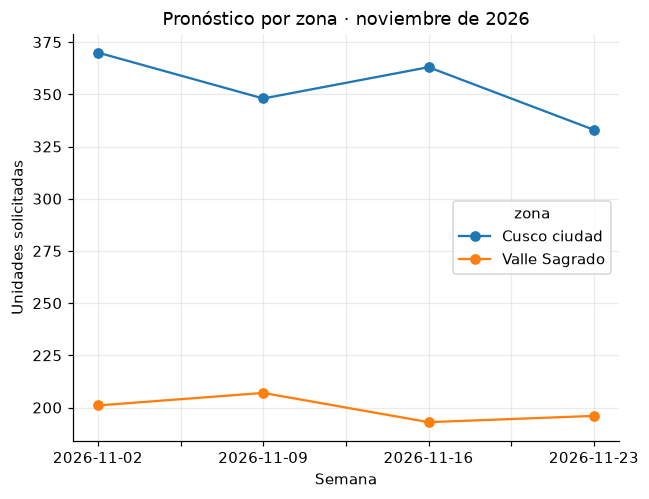

In [12]:
errores, pronostico, modelos, detalle_prueba = forecast(datos["demanda"])
display(modelos)
comparacion = (detalle_prueba.assign(error=lambda f: abs(f.real-f.predicho))
               .groupby("modelo")[["error","real"]].sum())
comparacion["WAPE"] = comparacion.error / comparacion.real
display(comparacion, pronostico.groupby("semana").unidades.sum().to_frame())
ax = pronostico.pivot_table(index="semana",columns="zona",values="unidades",aggfunc="sum").plot(marker="o")
ax.set(xlabel="Semana",ylabel="Unidades solicitadas",title="Pronóstico por zona · noviembre de 2026")
plt.show()


---
# Semana 11 · Optimizacion con PuLP

**Que decidir.** que cuentas contactar y cuantas unidades comprar de cada familia.

**Que entregar.**

1. Las **variables de decision** escritas con su significado y su unidad. Si son unidades
   indivisibles, son enteras (`cat='Integer'`).
2. La **funcion objetivo**: contribucion esperada neta, con los costes de intervencion dentro.
3. Las **restricciones**, una por recurso, cada una con su tope leido de `recursos.csv` con la
   funcion `tope()` de este cuaderno.
4. El **estado del solver**. Si dice `Infeasible`, no hay solucion y no se puede llamar optima a
   nada. Comprueben cada restriccion con tolerancia numerica despues de resolver.
5. La comparacion con la **politica actual**, bajo las mismas hipotesis, en margen y en uso de
   cada recurso.
6. Analisis de sensibilidad con los escenarios del enunciado.

**Los dos horizontes.** La retencion se valora a **seis meses** y la operacion a **cuatro
semanas**. Se reportan **por separado y no se suman**: los ingresos de un cliente contactado
estan en los dos calculos y sumarlos los contaria dos veces.

In [13]:
escenarios, despachos, contactos, ajustes = optimize(datos,pronostico,cartera,metricas["umbral"])
display(pd.Series(ajustes,name="Política actual antes de ajustar").to_frame(), escenarios.round(2))
display(despachos.query("capacidad == 1 and politica == 'Propuesta'"))
print("Los efectos de contacto son supuestos, no estimaciones causales. Se supone uso del incentivo por 30%.")
print("La regla histórica compra las unidades solicitadas en las últimas cuatro semanas. Si excede el presupuesto, reduce todas las familias en la misma proporción y redondea hacia abajo. El despacho maximiza el margen factible con ese inventario.")
print("La reserva para cada zona limita lo que puede consumir la otra. Las horas se aproximan con pedidos equivalentes y kg.")


,Política actual antes de ajustar
contactos_reconstruidos,200.0
excluidos_consentimiento,14.0
compra_bruta,103571.7
compra_bruta_unidades,2339.0


,capacidad,efecto,politica,solver,contactos,gasto_contactos,retencion_6m,margen_4s,compra,kg,horas,max_kg,max_horas,kg_cusco,kg_valle
0,1.00,0.00,Actual ajustada,Optimal,186,4185.0,-4185.00,32157.89,64823.87,7499.8,224.57,7500.0,320.0,4121.9,3377.9
1,1.00,0.04,Actual ajustada,Optimal,186,4185.0,-3366.42,32157.89,64823.87,7499.8,224.57,7500.0,320.0,4121.9,3377.9
2,1.00,0.09,Actual ajustada,Optimal,186,4185.0,-2343.20,32157.89,64823.87,7499.8,224.57,7500.0,320.0,4121.9,3377.9
3,1.00,0.00,Propuesta,Optimal,0,0.0,0.00,32652.42,50844.65,7499.3,227.35,7500.0,320.0,5173.9,2325.4
4,1.00,0.04,Propuesta,Optimal,0,0.0,0.00,32652.42,50844.65,7499.3,227.35,7500.0,320.0,5173.9,2325.4
5,1.00,0.09,Propuesta,Optimal,11,247.5,52.57,32652.42,50844.65,7499.3,227.35,7500.0,320.0,5173.9,2325.4
6,0.85,0.00,Actual ajustada,Optimal,186,4185.0,-4185.00,28779.55,64823.87,6373.8,199.10,6375.0,272.0,3645.4,2728.4
7,0.85,0.04,Actual ajustada,Optimal,186,4185.0,-3366.42,28779.55,64823.87,6373.8,199.10,6375.0,272.0,3645.4,2728.4
8,0.85,0.09,Actual ajustada,Optimal,186,4185.0,-2343.20,28779.55,64823.87,6373.8,199.10,6375.0,272.0,3645.4,2728.4
9,0.85,0.00,Propuesta,Optimal,0,0.0,0.00,29194.22,49010.67,6374.8,201.41,6375.0,272.0,4184.4,2190.4


,capacidad,politica,zona,familia,solicitado,despacho,compra_familia
12,1.0,Propuesta,Cusco ciudad,Detergentes y limpiadores,327,153,14
13,1.0,Propuesta,Valle Sagrado,Detergentes y limpiadores,181,0,14
14,1.0,Propuesta,Cusco ciudad,Desinfección,248,247,277
15,1.0,Propuesta,Valle Sagrado,Desinfección,124,124,277
16,1.0,Propuesta,Cusco ciudad,Empaque descartable,216,216,259
17,1.0,Propuesta,Valle Sagrado,Empaque descartable,193,193,259
18,1.0,Propuesta,Cusco ciudad,Papel e higiene,296,296,289
19,1.0,Propuesta,Valle Sagrado,Papel e higiene,127,127,289
20,1.0,Propuesta,Cusco ciudad,Menaje descartable,243,243,227
21,1.0,Propuesta,Valle Sagrado,Menaje descartable,90,90,227


Los efectos de contacto son supuestos, no estimaciones causales. Se supone uso del incentivo por 30%.
La regla histórica compra las unidades solicitadas en las últimas cuatro semanas. Si excede el presupuesto, reduce todas las familias en la misma proporción y redondea hacia abajo. El despacho maximiza el margen factible con ese inventario.
La reserva para cada zona limita lo que puede consumir la otra. Las horas se aproximan con pedidos equivalentes y kg.


---
# Semana 12 · Procesos internos

**Que entregar.**

1. **Deteccion de anomalias** en la tabla `operaciones`, con la regla escrita y el umbral
   justificado.
2. Una **carta de control apropiada** al tipo de dato: definan unidad de observacion, periodo
   base, estadistico y supuestos. Con muestras de tamano constante va una carta de medias.
3. Un **responsable por cada alerta** y que se hace cuando salta.

**Lo que no se puede hacer.** Ajustar los limites con el mismo periodo que se quiere vigilar, ni
quitar puntos solo para que la base salga estable. Si no hay una base estable de mas de 30
periodos, lo documentan como limitacion y proponen revisarla antes de activar alertas.

**La distincion que se pregunta en la sustentacion.** Los limites de control **no son
especificaciones de tolerancia**. Una unidad fuera de especificacion no prueba que el proceso
este fuera de control, y un proceso fuera de control puede estar produciendo dentro de
especificacion. Y una anomalia detectada es una senal para revisar, **no evidencia de fraude**.

alertas
sede          tipo                     
Cusco ciudad  nota_credito            3
              tiempo_entrega_h       86
Valle Sagrado nota_credito            2
              tiempo_entrega_h       55

size  sum
sede          base  base_estable           
Cusco ciudad  False False           43    0
              True  False          157    6
Valle Sagrado False False           43    3
              True  False          157    1

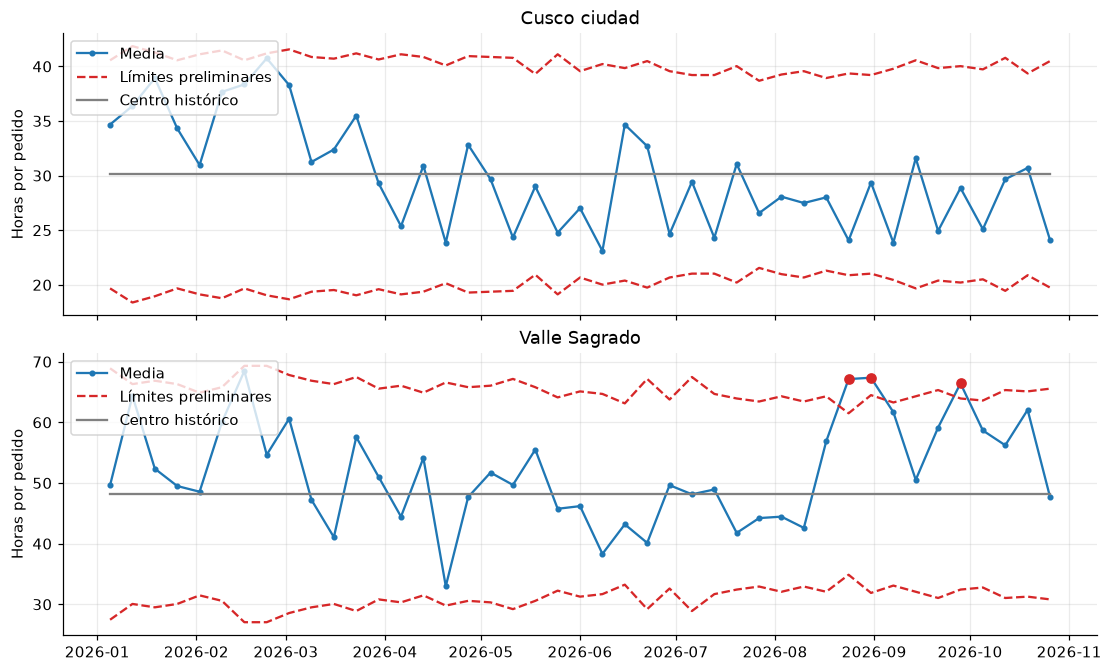

Logística contrasta pedidos y mensajes de retraso. Finanzas revisa notas de crédito contra la factura.
Si la base presenta señales, los límites son preliminares. Revisar causas y estabilidad antes de automatizar.


In [14]:
anomalias, carta = monitor(datos["operaciones"])
display(anomalias.groupby(["sede","tipo"]).size().rename("alertas").to_frame())
display(carta.groupby(["sede","base","base_estable"]).senal.agg(["size","sum"]))
fig,axes=plt.subplots(2,1,figsize=(10,6),sharex=True,layout="constrained")
for ax,(zona,g) in zip(axes,carta.groupby("sede")):
    x=g.loc[~g.base]
    ax.plot(x.semana,x.media,marker=".",label="Media")
    ax.plot(x.semana,x.lcs,ls="--",color="tab:red",label="Límites preliminares")
    ax.plot(x.semana,x.lci,ls="--",color="tab:red")
    ax.plot(x.semana,x.centro,color="gray",label="Centro histórico")
    ax.scatter(x.loc[x.senal,"semana"],x.loc[x.senal,"media"],color="tab:red",zorder=3)
    ax.set(title=zona,ylabel="Horas por pedido")
    ax.legend(loc="upper left")
plt.show()
print("Logística contrasta pedidos y mensajes de retraso. Finanzas revisa notas de crédito contra la factura.")
print("Si la base presenta señales, los límites son preliminares. Revisar causas y estabilidad antes de automatizar.")


---
# Semana 13 · Gobierno y explicabilidad

**Que entregar.**

1. **Contrato de datos** y **linaje**: de donde sale cada tabla, quien la produce, con que
   frecuencia, quien accede y cuanto tiempo se conserva.
2. **Auditoria por subgrupos** del modelo de la semana 9: recall y falsos positivos por zona,
   canal y segmento, **siempre con el denominador a la vista**. Si un subgrupo tiene pocos casos,
   se informa la limitacion en vez de comparar tasas que no se sostienen.
3. **SHAP** sobre el modelo, con una lectura en palabras: que variable pesa y en que direccion.
4. **Matriz normativa** con fuentes oficiales vigentes: Ley 29733 y su reglamento, Ley 31814 y su
   reglamento (DS 115-2025-PCM). Sobre el **EU AI Act**, digan si aplica o no y por que.

**La regla que atraviesa el caso.** Un cliente sin `consentimiento_contacto` no puede ser
contactado, aunque el modelo lo ponga primero en la lista. Comprueben cuantos de los contactos
que propone la politica actual tienen consentimiento: puede que no sean todos.

In [15]:
import shap
auditoria = audit(test,metricas["umbral"])
display(auditoria.round(3))
scaler, reg = modelo.steps[0][1], modelo.steps[1][1]
background = scaler.transform(train.sample(n=min(200,len(train)),random_state=SEMILLA)[FEATURES])
x = scaler.transform(test[FEATURES])
sv = shap.LinearExplainer(reg,background)(x).values
assert np.isfinite(sv).all()
shap_resumen=pd.DataFrame({"variable":FEATURES,"impacto_abs":abs(sv).mean(axis=0),
                          "coeficiente_log_odds":reg.coef_[0]}).sort_values("impacto_abs",ascending=False)
display(shap_resumen)
leader=shap_resumen.iloc[0]
sentido="incrementa" if leader.coeficiente_log_odds>0 else "reduce"
print(f"{leader.variable} tiene el mayor SHAP absoluto medio en prueba. Un valor más alto {sentido} el log-odds de churn en el modelo, manteniendo las demás variables.")
print("SHAP explica el modelo asociativo. La auditoría compara tasas con sus denominadores y marca grupos con menos de 20 positivos o negativos.")


,dimension,subgrupo,n,tn,fp,fn,tp,precision,recall,fpr,positivos,negativos,cobertura,muestra_pequena
0,zona,Cusco ciudad,79,12,44,0,23,0.343,1.000,0.786,23,56,0.0,False
1,zona,Valle Sagrado,31,0,14,1,16,0.533,0.941,1.000,17,14,0.0,True
2,tamano_negocio,mediano,21,5,8,0,8,0.500,1.000,0.615,8,13,0.0,True
3,tamano_negocio,micro,44,2,23,0,19,0.452,1.000,0.920,19,25,0.0,True
4,tamano_negocio,pequeño,45,5,27,1,12,0.308,0.923,0.844,13,32,0.0,True
5,canal,ejecutivo comercial,56,5,31,1,19,0.380,0.950,0.861,20,36,0.0,False
6,canal,teléfono,34,4,18,0,12,0.400,1.000,0.818,12,22,0.0,True
7,canal,web,20,3,9,0,8,0.471,1.000,0.750,8,12,0.0,True
8,segmento,Hotel pequeño,31,2,15,0,14,0.483,1.000,0.882,14,17,0.0,True
9,segmento,Restaurante,79,10,43,1,25,0.368,0.962,0.811,26,53,0.0,False


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


,variable,impacto_abs,coeficiente_log_odds
2,ingreso180,0.670116,0.937250
3,margen180,0.662116,-0.926019
0,recencia,0.314940,0.374264
1,frecuencia,0.167647,-0.216495
4,retraso180,0.054902,0.070488
5,creditos180,0.036687,0.048290


ingreso180 tiene el mayor SHAP absoluto medio en prueba. Un valor más alto incrementa el log-odds de churn en el modelo, manteniendo las demás variables.
SHAP explica el modelo asociativo. La auditoría compara tasas con sus denominadores y marca grupos con menos de 20 positivos o negativos.


---
# Semana 14 · Asistente analitico y checkpoint

**Que entregar.**

1. Un asistente **text-to-SQL de solo lectura** sobre la base que guardo el Paso 5 de este
   cuaderno, o un **RAG** sobre la tabla `documentos`.
2. Un **conjunto fijo de evaluacion** de 20 preguntas, definido *antes* de probar el asistente.
   No todas deben tener respuesta: incluyan preguntas ambiguas, preguntas sobre datos a los que el
   asistente no tiene acceso y alguna instruccion adversaria. Ante esas, **la respuesta correcta es
   abstenerse**.
3. **Tasa de acierto y tasa de alucinacion**, con la tabla pregunta por pregunta.
4. Una **linea base determinista** (consultas SQL escritas a mano) contra la que comparar. Si no
   llegaron a ejecutar un LLM, lo dicen: el LLM solo se reporta si de verdad se ejecuto.

**Esta semana se entrega el checkpoint (4 puntos del informe gerencial).**

### Comparación de motores

La base determinista recupera frases literales y se abstiene cuando falta evidencia pertinente. En la evaluación local, Qwen elige entre dos extractos candidatos y puede abstenerse. El filtro se abstuvo antes de inferencia en ocho preguntas y el modelo se ejecutó en doce. Se conserva el registro de esa ejecución en las salidas. Para repetir la inferencia local, establezca la variable de entorno PMD2_MODELO_LOCAL en Qwen/Qwen2.5-0.5B-Instruct antes de ejecutar.

El indicador «sin sustento» marca una respuesta en un caso de abstención o una cita de una fuente distinta a la esperada. La exactitud también exige los fragmentos mínimos de la respuesta.


In [16]:
documentos=datos["documentos"].to_dict("records")
fuentes=corpus(documentos)
casos=json.loads((PROYECTO/"preguntas.json").read_text(encoding="utf-8"))
assert len(casos)==20 and sum(bool(c["fuente"]) for c in casos)==12
motor = os.environ.get("PMD2_MODELO_LOCAL")
pruebas, estado_llm, uso = evaluate(fuentes,casos,model=motor)
if not motor:
    registro = PROYECTO / "salidas" / "qwen_ejecucion.json"
    if not registro.is_file():
        registro.parent.mkdir(exist_ok=True)
        urlretrieve("https://raw.githubusercontent.com/jhadir08/analitica-empresarial-integrada/main/PMD2/salidas/qwen_ejecucion.json", registro)
    prueba_llm = json.loads(registro.read_text(encoding="utf-8"))
    pruebas.extend(prueba_llm["filas"])
    estado_llm = "Comparación local registrada. " + prueba_llm["estado"]
    uso = prueba_llm["uso"]
evaluacion = pd.DataFrame(pruebas)
indicadores = evaluacion.groupby("motor")[["acierto","sin_sustento"]].mean()
display(indicadores, evaluacion[["motor","id","tipo","fuentes","acierto","defecto"]])
print(estado_llm)


,acierto,sin_sustento
motor,,
Determinista,1.0,0.0
Qwen/Qwen2.5-0.5B-Instruct,0.9,0.0


,motor,id,tipo,fuentes,acierto,defecto
0,Determinista,1,respondible,SS-DOC-01 v3.1,True,
1,Determinista,2,respondible,SS-DOC-01 v3.1,True,
2,Determinista,3,respondible,SS-DOC-01 v3.1,True,
3,Determinista,4,respondible,SS-DOC-01 v3.1,True,
4,Determinista,5,respondible,SS-DOC-01 v3.1,True,
5,Determinista,6,respondible,SS-DOC-02 v2.0,True,
6,Determinista,7,respondible,SS-DOC-02 v2.0,True,
7,Determinista,8,respondible,SS-DOC-02 v2.0,True,
8,Determinista,9,respondible,SS-DOC-03 v2.2,True,
9,Determinista,10,respondible,SS-DOC-03 v2.2,True,


Comparación local registrada. LLM ejecutado en lote. Tiempo total, incluida la carga: 111556 ms.


---
# Semana 15 · Producto y comunicacion

**Que entregar.**

1. **Streamlit desplegado**, con enlace que funcione desde cualquier computadora: riesgo y
   umbral, demanda pronosticada, la optimizacion con sus escenarios, la carta de control, el
   gobierno y el asistente con su evaluacion a la vista.
2. **Informe gerencial**: la decision, la evidencia y lo que cuesta equivocarse. Para gerencia,
   no para el profesor.
3. **Hoja de ruta** analitica.
4. **Colab reproducible**: se ejecuta de principio a fin, sin rutas de la computadora de nadie,
   y da los mismos numeros. Por eso el Paso 0 fija la semilla y el Paso 2 usa un solo hilo.
5. **Ensayo cronometrado del pitch.** En la sustentacion hay 7 puntos grupales y 13 individuales:
   cada integrante tiene que poder defender cualquier parte del proyecto, no solo la suya.

In [17]:
def records(frame):
    return json.loads(frame.to_json(orient="records", date_format="iso", force_ascii=False))

frames={"umbrales":umbrales,"errores_pronostico":errores,"pronostico":pronostico,
        "comparacion_prueba":detalle_prueba,"escenarios":escenarios,"despachos":despachos,
        "carta_control":carta,"anomalias":anomalias,"auditoria":auditoria,
        "shap":shap_resumen,"evaluacion_asistente":evaluacion,"cortes":cortes}
for archivo,frame in frames.items():
    frame.to_csv(SALIDAS/f"{archivo}.csv",index=False,encoding="utf-8-sig")
contactos.to_csv(SALIDAS/"contactos_seudonimizados.csv",index=False)
snapshot={name:records(frames[name]) for name in
          ("pronostico","escenarios","despachos","carta_control","auditoria","shap","evaluacion_asistente","umbrales")}
snapshot.update(metricas=json.loads(pd.Series(metricas).to_json()), ajustes=ajustes, fuentes=fuentes,
                llm=estado_llm, uso_llm=uso,
                anomalias=records(anomalias.groupby(["sede","tipo"]).size().rename("alertas").reset_index()))
(SALIDAS/"tablero.json").write_text(json.dumps(snapshot,ensure_ascii=False,indent=2),encoding="utf-8")
print("Salidas disponibles en",SALIDAS)


Salidas disponibles en salidas


## Paquete del checkpoint

- El notebook ejecutado contiene los resultados de las semanas 9 a 14.
- En salidas están las tablas de evaluación, el registro de defectos y las cifras que consume el tablero.
- El documento Gobierno y pendientes incluye linaje, matriz normativa, responsables y el plan de integración.
